In [1]:

# 🌱 AI-Based Crop Disease Detection
# Step 1: Import libraries and prepare the project

import sys
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Python version:", sys.version)
print("NumPy version:", np.__version__)
print("Project setup completed! 🚀")


Python version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
NumPy version: 2.1.3
Project setup completed! 🚀


In [2]:

%pip install -q tensorflow streamlit pillow
print("AI and image-processing libraries installed! 🧠")


AI and image-processing libraries installed! 🧠


In [3]:

import tensorflow as tf
from PIL import Image

print("TensorFlow version:", tf.__version__)
print("AI engine ready! 🧠")



TensorFlow version: 2.21.0
AI engine ready! 🧠


In [4]:

%pip install -q transformers torch torchvision


In [5]:

from transformers import pipeline

MODEL_NAME = (
    "linkanjarad/"
    "mobilenet_v2_1.0_224-plant-disease-identification"
)

print("Loading plant disease model... 🌱")

plant_model = pipeline(
    "image-classification",
    model=MODEL_NAME
)

print("AI model loaded successfully! 🧠")


Loading plant disease model... 🌱


config.json:   0%|          | 0.00/3.57k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 9.34MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/408 [00:00<?, ?B/s]

ValueError: Unrecognized image processor in linkanjarad/mobilenet_v2_1.0_224-plant-disease-identification. Should have a `image_processor_type` key in its preprocessor_config.json of config.json, or one of the following `model_type` keys in its config.json: aria, beit, bit, blip, bridgetower, chameleon, chinese_clip, chmv2, clip, cohere2_vision, cohere_compass, conditional_detr, convnext, cosmos3_edge, deepseek_ocr2, deepseek_vl, deepseek_vl_hybrid, deformable_detr, deit, depth_pro, detr, dinov3_vit, dpt, efficientloftr, efficientnet, eomt, ernie4_5_vl_moe, flava, fuyu, gemma3, gemma4, gemma4_unified, glm46v, glm4v, glm5_next, glm_image, glmga, glpn, got_ocr2, grounding-dino, hunyuan_vl, idefics, idefics2, idefics3, imagegpt, janus, kimi_k25, layoutlmv2, layoutlmv3, levit, lfm2_vl, lightglue, llama4, llava, llava_next, llava_onevision, mask2former, maskformer, minicpmv4_6, minimax_m3_vl, mllama, mobilenet_v1, mobilenet_v2, mobilevit, molmo2, muse_glimmer, nemotron_h_omni, neomme, nouga

In [6]:

import torch
from transformers import AutoImageProcessor, AutoModelForImageClassification

MODEL_NAME = "linkanjarad/mobilenet_v2_1.0_224-plant-disease-identification"

print("Loading image processor...")
processor = AutoImageProcessor.from_pretrained(
    "google/mobilenet_v2_1.0_224"
)

print("Loading trained plant disease model...")
model = AutoModelForImageClassification.from_pretrained(MODEL_NAME)
model.eval()

print("AI model loaded successfully! 🌱")
print("Number of classes:", model.config.num_labels)


Loading image processor...


preprocessor_config.json:   0%|          | 0.00/406 [00:00<?, ?B/s]

Loading trained plant disease model...


Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

AI model loaded successfully! 🌱
Number of classes: 38


Saving apple_healthy.png to apple_healthy.png


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127807 (\N{HERB}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


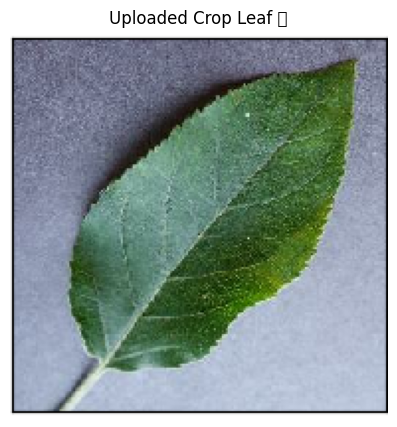


🌱 Crop Disease Detection Results
Healthy Apple: 99.50%
Apple Scab: 0.47%
Healthy Peach Plant: 0.01%
Healthy Soybean Plant: 0.00%
Healthy Strawberry Plant: 0.00%


In [7]:

from google.colab import files
from PIL import Image
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

# Upload a leaf image
uploaded = files.upload()

image_path = next(iter(uploaded))
image = Image.open(image_path).convert("RGB")

# Display the uploaded image
plt.figure(figsize=(5, 5))
plt.imshow(image)
plt.axis("off")
plt.title("Uploaded Crop Leaf 🌿")
plt.show()

# Preprocess image using MobileNetV2 processor
inputs = processor(images=image, return_tensors="pt")

# Predict using the trained model
with torch.no_grad():
    outputs = model(**inputs)
    probabilities = F.softmax(outputs.logits, dim=1)[0]

# Show top 5 predictions
top_results = torch.topk(probabilities, k=5)

print("\n🌱 Crop Disease Detection Results")
for score, index in zip(top_results.values, top_results.indices):
    label = model.config.id2label[index.item()]
    print(f"{label}: {score.item() * 100:.2f}%")


🌱 SMART FARMING DASHBOARD
-----------------------------------
Temperature (°C): 26
Humidity (%): 80
Soil Moisture (%): 78


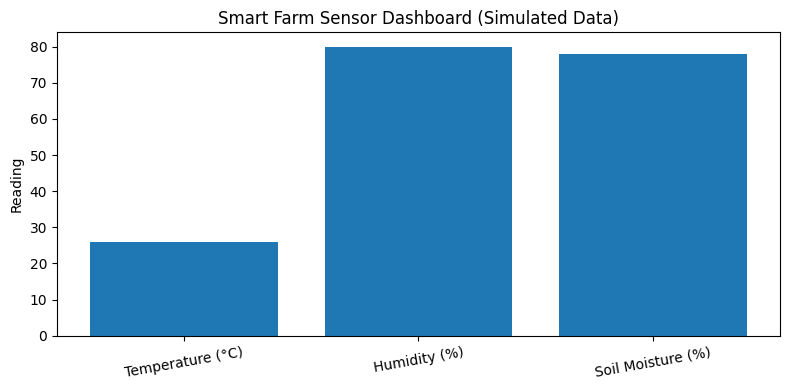


Dashboard generated successfully! 🚀


In [8]:

import random
import pandas as pd
import matplotlib.pyplot as plt

# Smart farming recommendation rules
def get_recommendation(disease_name):
    name = disease_name.lower()

    if "healthy" in name:
        return "Plant appears healthy. Continue regular monitoring and proper watering."

    elif "early blight" in name:
        return "Remove badly affected leaves and avoid overhead watering. Confirm diagnosis before treatment."

    elif "late blight" in name:
        return "Isolate affected plants where practical and seek local agricultural guidance promptly."

    elif "bacterial" in name:
        return "Avoid handling wet plants, clean tools, and seek advice before applying treatment."

    elif "rust" in name:
        return "Monitor the spread and seek crop-specific guidance before choosing a treatment."

    else:
        return "Check the predicted disease with a local agricultural expert before taking action."


# Simulated sensor readings (demo only)
sensor_data = {
    "Temperature (°C)": random.randint(22, 36),
    "Humidity (%)": random.randint(40, 90),
    "Soil Moisture (%)": random.randint(20, 80)
}

# Display the dashboard
print("🌱 SMART FARMING DASHBOARD")
print("-" * 35)

for sensor, value in sensor_data.items():
    print(f"{sensor}: {value}")

plt.figure(figsize=(8, 4))
plt.bar(sensor_data.keys(), sensor_data.values())
plt.title("Smart Farm Sensor Dashboard (Simulated Data)")
plt.ylabel("Reading")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

print("\nDashboard generated successfully! 🚀")


In [9]:

# Use the top prediction from the previous detection step
predicted_index = top_results.indices[0].item()
predicted_disease = model.config.id2label[predicted_index]
confidence = top_results.values[0].item() * 100

print("🌿 CROP DISEASE REPORT")
print("-" * 35)
print("Predicted class:", predicted_disease)
print(f"Model confidence: {confidence:.2f}%")
print("\nRecommended next step:")
print(get_recommendation(predicted_disease))


🌿 CROP DISEASE REPORT
-----------------------------------
Predicted class: Healthy Apple
Model confidence: 99.50%

Recommended next step:
Plant appears healthy. Continue regular monitoring and proper watering.


In [10]:

%pip install -q gradio


In [11]:

import gradio as gr
import torch
import torch.nn.functional as F


def predict_leaf(image):
    if image is None:
        return "Please upload a leaf image.", "No image uploaded."

    image = image.convert("RGB")
    inputs = processor(images=image, return_tensors="pt")

    with torch.no_grad():
        outputs = model(**inputs)
        probabilities = torch.nn.functional.softmax(
            outputs.logits, dim=1
        )[0]

    top = torch.topk(probabilities, k=3)

    results = []
    for score, index in zip(top.values, top.indices):
        label = model.config.id2label[index.item()]
        results.append(
            f"{label}: {score.item() * 100:.2f}%"
        )

    best_score = top.values[0].item() * 100
    best_label = model.config.id2label[
        top.indices[0].item()
    ]

    report = "Top 3 Predictions:\n" + "\n".join(results)

    if best_score < 60:
        recommendation = (
            "⚠️ Low-confidence prediction.\n"
            "Try a clearer image and confirm the result "
            "with an agricultural expert."
        )
    else:
        recommendation = get_recommendation(best_label)

    return report, recommendation







import gradio as gr

with gr.Blocks(theme=gr.themes.Soft()) as demo:
    gr.Markdown(
        """
        # 🌱 AI-Based Crop Disease Detection
        ### Smart Farming Support System

        Upload a clear crop-leaf image to get an AI prediction
        and basic crop-care guidance.

        **How to use:**
        1. Upload an image of a single leaf.
        2. Click Predict Disease.
        3. Review the top predictions and recommendations.
        """
    )

    with gr.Row():
        image_input = gr.Image(
            type="pil",
            label="Upload Crop Leaf Image"
        )

        with gr.Column():
            prediction_output = gr.Textbox(
                label="AI Disease Predictions",
                lines=5
            )

            recommendation_output = gr.Textbox(
                label="Crop-Care Recommendation",
                lines=4
            )

    predict_button = gr.Button(
        "🔍 Predict Disease",
        variant="primary"
    )

    predict_button.click(
        fn=predict_leaf,
        inputs=image_input,
        outputs=[prediction_output, recommendation_output]
    )

    gr.Markdown(
        """
        ---
        **Disclaimer:** This tool provides AI-generated predictions
        for educational purposes. Confirm suspected diseases with
        an agricultural expert before applying treatments.
        """
    )

demo.launch(share=True)


/tmp/ipykernel_3604/2350624664.py:54: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft()) as demo:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://b278ddc8885fe1bd35.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [12]:
demo.launch(share=True)

Rerunning server... use `close()` to stop if you need to change `launch()` parameters.
----
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://b278ddc8885fe1bd35.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [13]:
print("Model:", model.config._name_or_path)
print("Number of classes:", model.config.num_labels)
print("Processor:", processor.__class__.__name__)
print("Image size:", processor.size)
print("Normalization:", processor.image_mean, processor.image_std)
print("First 10 labels:")
for i in range(min(10, model.config.num_labels)):
    print(i, model.config.id2label[i])

Model: linkanjarad/mobilenet_v2_1.0_224-plant-disease-identification
Number of classes: 38
Processor: MobileNetV2ImageProcessor
Image size: SizeDict(height=None, width=None, longest_edge=None, shortest_edge=256, max_height=None, max_width=None, min_pixels=None, max_pixels=None)
Normalization: (0.5, 0.5, 0.5) (0.5, 0.5, 0.5)
First 10 labels:
0 Apple Scab
1 Apple with Black Rot
2 Cedar Apple Rust
3 Healthy Apple
4 Healthy Blueberry Plant
5 Cherry with Powdery Mildew
6 Healthy Cherry Plant
7 Corn (Maize) with Cercospora and Gray Leaf Spot
8 Corn (Maize) with Common Rust
9 Corn (Maize) with Northern Leaf Blight


In [14]:
print("Resize:", processor.do_resize)
print("Center crop:", processor.do_center_crop)
print("Crop size:", processor.crop_size)
print("Rescale:", processor.do_rescale)
print("Rescale factor:", processor.rescale_factor)

Resize: True
Center crop: True
Crop size: SizeDict(height=224, width=224, longest_edge=None, shortest_edge=None, max_height=None, max_width=None, min_pixels=None, max_pixels=None)
Rescale: True
Rescale factor: 0.00392156862745098


In [15]:
import torch
import torch.nn.functional as F

inputs = processor(images=image, return_tensors="pt")

with torch.no_grad():
    logits = model(**inputs).logits
    probs = F.softmax(logits, dim=1)[0]

top = torch.topk(probs, 5)

for score, idx in zip(top.values, top.indices):
    print(f"{model.config.id2label[idx.item()]}: {score.item()*100:.2f}%")

print("\nInput tensor shape:", inputs["pixel_values"].shape)
print("Pixel range:",
      inputs["pixel_values"].min().item(),
      inputs["pixel_values"].max().item())

Healthy Apple: 99.50%
Apple Scab: 0.47%
Healthy Peach Plant: 0.01%
Healthy Soybean Plant: 0.00%
Healthy Strawberry Plant: 0.00%

Input tensor shape: torch.Size([1, 3, 224, 224])
Pixel range: -1.0 0.8901960849761963


In [16]:
from transformers import AutoImageProcessor

MODEL_NAME = "linkanjarad/mobilenet_v2_1.0_224-plant-disease-identification"

processor = AutoImageProcessor.from_pretrained(MODEL_NAME)

print(processor)

ValueError: Unrecognized image processor in linkanjarad/mobilenet_v2_1.0_224-plant-disease-identification. Should have a `image_processor_type` key in its preprocessor_config.json of config.json, or one of the following `model_type` keys in its config.json: aria, beit, bit, blip, bridgetower, chameleon, chinese_clip, chmv2, clip, cohere2_vision, cohere_compass, conditional_detr, convnext, cosmos3_edge, deepseek_ocr2, deepseek_vl, deepseek_vl_hybrid, deformable_detr, deit, depth_pro, detr, dinov3_vit, dpt, efficientloftr, efficientnet, eomt, ernie4_5_vl_moe, flava, fuyu, gemma3, gemma4, gemma4_unified, glm46v, glm4v, glm5_next, glm_image, glmga, glpn, got_ocr2, grounding-dino, hunyuan_vl, idefics, idefics2, idefics3, imagegpt, janus, kimi_k25, layoutlmv2, layoutlmv3, levit, lfm2_vl, lightglue, llama4, llava, llava_next, llava_onevision, mask2former, maskformer, minicpmv4_6, minimax_m3_vl, mllama, mobilenet_v1, mobilenet_v2, mobilevit, molmo2, muse_glimmer, nemotron_h_omni, neomme, nouga

In [ ]:
from transformers import AutoImageProcessor

processor = AutoImageProcessor.from_pretrained(
    "google/mobilenet_v2_1.0_224"
)

print("Processor restored:", processor)

In [ ]:
from PIL import Image
from google.colab import files
import torch
import torch.nn.functional as F

uploaded = files.upload()
image_path = next(iter(uploaded))

test_image = Image.open(image_path).convert("RGB")

inputs = processor(images=test_image, return_tensors="pt")

with torch.no_grad():
    outputs = model(**inputs)
    probabilities = F.softmax(outputs.logits, dim=1)[0]

top = torch.topk(probabilities, 5)

print("Expected label: Tomato with Bacterial Spot")
print("\nModel predictions:")

for score, idx in zip(top.values, top.indices):
    print(f"{model.config.id2label[idx.item()]}: {score.item()*100:.2f}%")

In [ ]:
print("Model architecture:", model.config.architectures)
print("Model labels:")
for i, label in model.config.id2label.items():
    print(i, label)